In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Dataset .csv to Dataset  (1).csv


In [ ]:
df = pd.read_csv("/content/Dataset .csv")

df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (9551, 21)

Column Names:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']

Data Types:
Restaurant ID             int64
Restaurant Name          object
Country Code              int64
City                     object
Address                  object
Locality                 object
Locality Verbose         object
Longitude               float64
Latitude                float64
Cuisines                 object
Average Cost for two      int64
Currency                 object
Has Table booking        object
Has Online delivery      object
Is delivering now        object
Switch to order menu     object
Price range               int64
Aggregate rating        float64
Rating color             obje

In [ ]:
print("Target Variable: Aggregate rating")

print("\nTarget Statistics:")
print(df["Aggregate rating"].describe())

Target Variable: Aggregate rating

Target Statistics:
count    9551.000000
mean        2.666370
std         1.516378
min         0.000000
25%         2.500000
50%         3.200000
75%         3.700000
max         4.900000
Name: Aggregate rating, dtype: float64


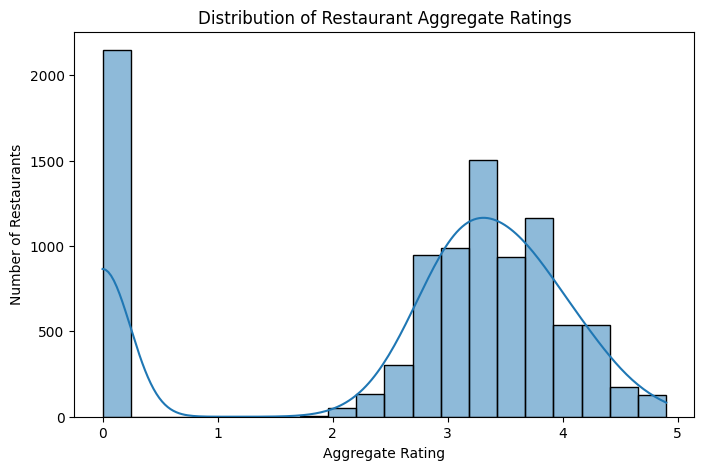

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Aggregate rating"], bins=20, kde=True)

plt.title("Distribution of Restaurant Aggregate Ratings")
plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")

plt.show()

In [ ]:
X = df.drop(
    columns=[
        "Aggregate rating",
        "Rating color",
        "Rating text"
    ]
)

y = df["Aggregate rating"]
X = X.drop(columns=["Restaurant ID"])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 7640
Testing samples: 1911


In [ ]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Country Code', 'Longitude', 'Latitude', 'Average Cost for two', 'Price range', 'Votes']

Categorical Features:
['Restaurant Name', 'City', 'Address', 'Locality', 'Locality Verbose', 'Cuisines', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu']


In [ ]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        max_depth=10
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

In [ ]:
results = []

trained_models = {}

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        max_depth=10
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=50,
        random_state=42,
        n_jobs=-1,
        max_depth=10
    )
}

for name, model in models.items():

    print(f"Training {name}...")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

    print(f"{name} completed.")

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="R2 Score",
    ascending=False
)

,Model,MSE,RMSE,R2 Score
2,Random Forest,8.816839e-02,0.296932,9.612635e-01
1,Decision Tree,1.076783e-01,0.328144,9.526919e-01
0,Linear Regression,4.128523e+06,2031.876816,-1.813850e+06


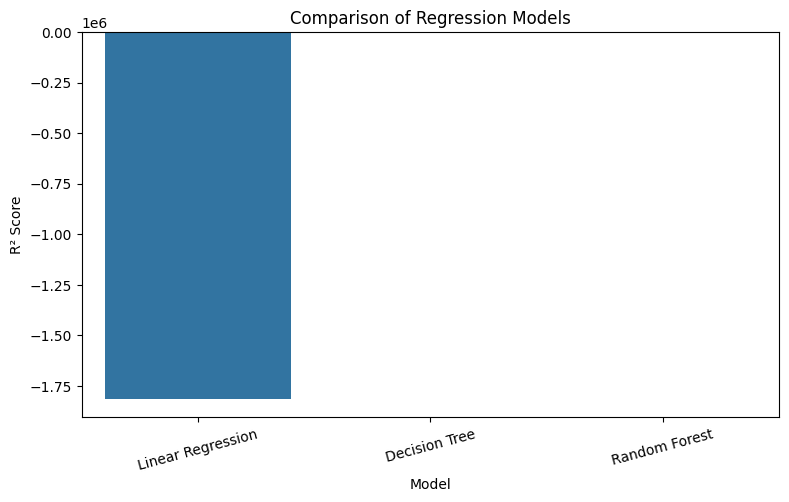

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Comparison of Regression Models")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.xticks(rotation=15)

plt.show()

In [ ]:
best_model_name = results_df.loc[
    results_df["R2 Score"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

print("Best Performing Model:", best_model_name)

Best Performing Model: Random Forest


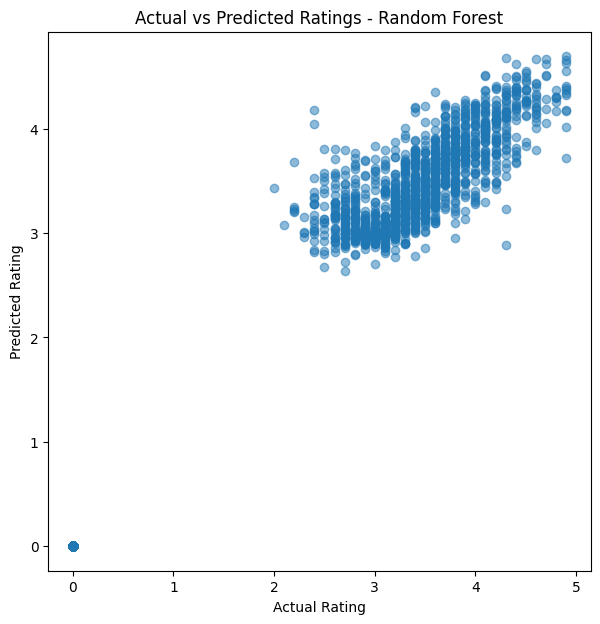

In [ ]:
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title(
    f"Actual vs Predicted Ratings - {best_model_name}"
)

plt.show()

In [ ]:
rf_pipeline = trained_models["Random Forest"]

feature_names = (
    rf_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    rf_pipeline
    .named_steps["model"]
    .feature_importances_
)

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df.head(15)

,Feature,Importance
5,num__Votes,0.943483
1,num__Longitude,0.010395
2,num__Latitude,0.007967
3,num__Average Cost for two,0.003772
0,num__Country Code,0.002703
17150,cat__Currency_Indian Rupees(Rs.),0.000589
16727,"cat__Cuisines_North Indian, Chinese",0.000507
4,num__Price range,0.000458
1719,cat__Restaurant Name_Domino's Pizza,0.000340
17147,cat__Currency_Brazilian Real(R$),0.000338


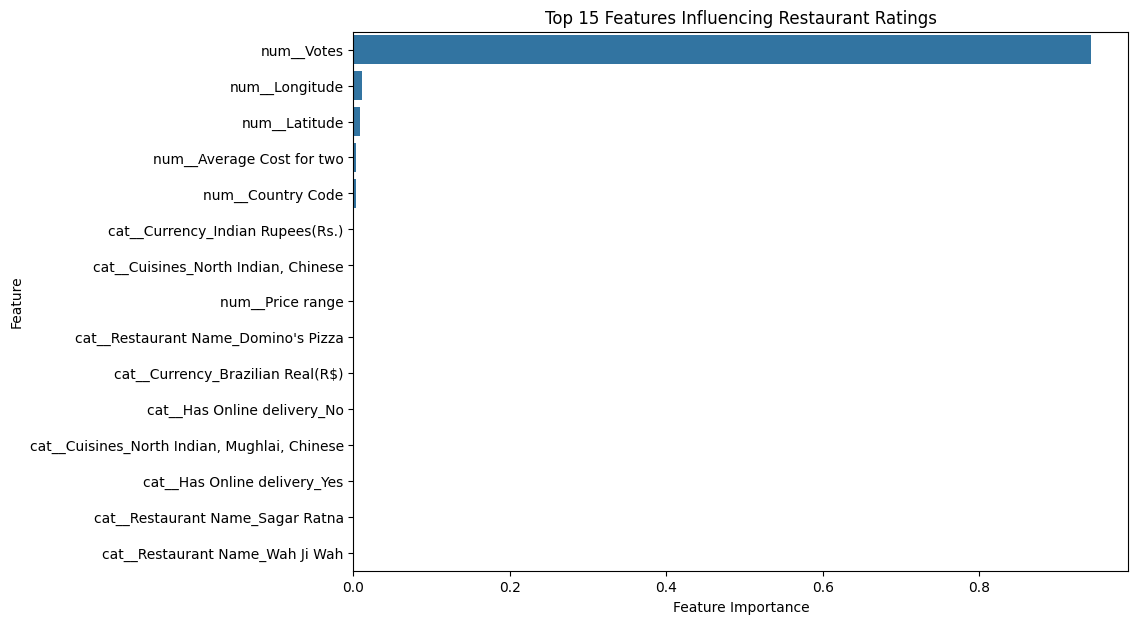

In [ ]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Restaurant Ratings")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

In [ ]:
final_results = results_df.copy()

final_results = final_results.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

final_results

,Model,MSE,RMSE,R2 Score
0,Random Forest,8.816839e-02,0.296932,9.612635e-01
1,Decision Tree,1.076783e-01,0.328144,9.526919e-01
2,Linear Regression,4.128523e+06,2031.876816,-1.813850e+06


## Conclusion

The objective of this task was to develop a machine learning model to predict
the aggregate rating of restaurants using other available restaurant features.

The dataset was preprocessed by handling missing values and encoding
categorical variables. The data was then divided into training and testing
sets.

Three regression models were evaluated:

- Linear Regression
- Decision Tree Regression
- Random Forest Regression

Among the evaluated models, Random Forest performed the best with an R² score
of 0.9613 and an RMSE of 0.2969 on the test dataset. The Decision Tree model
also performed well with an R² score of 0.9527, while Linear Regression showed
very poor performance on this dataset.

Feature importance analysis using the Random Forest model showed that the
number of votes was the most influential feature among the features used for
prediction. Geographic features such as longitude and latitude had much
smaller relative importance, while other numerical and categorical features
also contributed to the model to varying degrees.

Overall, the results demonstrate that tree-based ensemble methods can model
the relationships in this restaurant dataset effectively and can provide
accurate predictions of restaurant aggregate ratings.